# Mobile Game A/B Test: Does Moving the Progress Gate Hurt Retention?

**Business question:** Cookie Cats moved its first gate from level 30 to level 40. Did this change retention, and should it be shipped?

**Columns:**
- `userid` – unique player
- `version` – gate_30 (control) / gate_40 (test)
- `sum_gamerounds` – rounds played in first 14 days
- `retention_1` / `retention_7` – returned on day 1 / day 7

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/cookie_cats.csv')
print(df.shape)
print(df.head())
print(df.dtypes)

(90189, 5)
   userid  version  sum_gamerounds  retention_1  retention_7
0     116  gate_30               3        False        False
1     337  gate_30              38         True        False
2     377  gate_40             165         True        False
3     483  gate_40               1        False        False
4     488  gate_40             179         True         True
userid             int64
version           object
sum_gamerounds     int64
retention_1         bool
retention_7         bool
dtype: object


In [2]:
# Missing values and duplicates
print(df.isnull().sum())
print("Duplicate users:", df['userid'].duplicated().sum())

# Outliers in game rounds
print(df['sum_gamerounds'].describe())
print(df.sort_values('sum_gamerounds', ascending=False).head())

userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64
Duplicate users: 0
count    90189.000000
mean        51.872457
std        195.050858
min          0.000000
25%          5.000000
50%         16.000000
75%         51.000000
max      49854.000000
Name: sum_gamerounds, dtype: float64
        userid  version  sum_gamerounds  retention_1  retention_7
57702  6390605  gate_30           49854        False         True
7912    871500  gate_30            2961         True         True
29417  3271615  gate_40            2640         True        False
43671  4832608  gate_30            2438         True         True
48188  5346171  gate_40            2294         True         True


## Data Quality
- No missing values, no duplicate users.
- `sum_gamerounds` is highly right-skewed (median 16, mean 51.9).
- Removed 1 outlier (49,854 rounds in 14 days with no day-1 return — likely a logging error). Next-highest values (~3,000) are plausible and kept.

In [3]:
# Remove the impossible outlier
df = df[df['sum_gamerounds'] < df['sum_gamerounds'].max()]
print("Rows after removing outlier:", len(df))

# Sample Ratio Mismatch check: was the split fair?
from scipy.stats import chisquare
counts = df['version'].value_counts()
print(counts)
stat, p = chisquare(counts)
print(f"SRM p-value: {p:.4f}")

Rows after removing outlier: 90188
version
gate_40    45489
gate_30    44699
Name: count, dtype: int64
SRM p-value: 0.0085


## Sample Ratio Mismatch (SRM) Check
- gate_30: 44,699 | gate_40: 45,489 (49.6% / 50.4%)
- Chi-square SRM p-value = 0.0085 → split deviates significantly from 50/50.
- In production, this would trigger an investigation of the assignment/logging pipeline before trusting results.
- Imbalance is small (<1 pp), so analysis proceeds, but results are reported with this limitation.

Players with 0 rounds: 3994


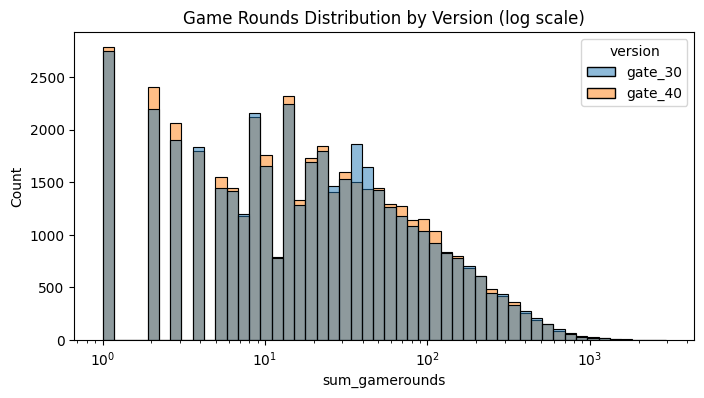

         players  median_rounds  avg_rounds  retention_1  retention_7
version                                                              
gate_30    44699           17.0   51.342111     0.448198     0.190183
gate_40    45489           16.0   51.298776     0.442283     0.182000


In [4]:
# Players who never played
print("Players with 0 rounds:", (df['sum_gamerounds'] == 0).sum())

# Distribution of rounds (log scale because it's very skewed)
plt.figure(figsize=(8,4))
sns.histplot(data=df[df['sum_gamerounds'] > 0], x='sum_gamerounds', hue='version',
             bins=50, log_scale=(True, False))
plt.title('Game Rounds Distribution by Version (log scale)')
plt.savefig('../images/rounds_distribution.png', bbox_inches='tight')
plt.show()

# Retention by version
summary = df.groupby('version').agg(
    players=('userid','count'),
    median_rounds=('sum_gamerounds','median'),
    avg_rounds=('sum_gamerounds','mean'),
    retention_1=('retention_1','mean'),
    retention_7=('retention_7','mean')
)
print(summary)

## Exploratory Analysis
- 3,994 players (4.4%) installed but never played — unaffected by the gate.
- Engagement is nearly identical: median rounds 17 (gate_30) vs 16 (gate_40); mean ~51.3 for both.
- Retention is slightly higher for gate_30:
  - Day-1: 44.82% vs 44.23% (−0.59 pp for gate_40)
  - Day-7: 19.02% vs 18.20% (−0.82 pp for gate_40)
- Distribution shows a gate_30 spike near 30–40 rounds, suggesting gate position affects where players pause. Investigated in segmentation below.
- Next: test whether these differences are statistically significant.

In [5]:
import duckdb
con = duckdb.connect()
con.register('players', df)

query = """
SELECT
    version,
    CASE
        WHEN sum_gamerounds = 0   THEN '0 rounds'
        WHEN sum_gamerounds < 30  THEN '1-29'
        WHEN sum_gamerounds < 40  THEN '30-39'
        WHEN sum_gamerounds < 100 THEN '40-99'
        ELSE '100+'
    END AS engagement_segment,
    COUNT(*) AS players,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (PARTITION BY version), 2) AS pct_of_version,
    ROUND(AVG(CAST(retention_1 AS INT)) * 100, 2) AS ret1_pct,
    ROUND(AVG(CAST(retention_7 AS INT)) * 100, 2) AS ret7_pct
FROM players
GROUP BY version, engagement_segment
ORDER BY MIN(sum_gamerounds), version
"""
seg = con.execute(query).df()
print(seg)
seg.to_csv('../data/segment_results.csv', index=False)

   version engagement_segment  players  pct_of_version  ret1_pct  ret7_pct
0  gate_30           0 rounds     1937            4.33      2.12      0.83
1  gate_40           0 rounds     2057            4.52      2.24      0.63
2  gate_30               1-29    26107           58.41     25.48      4.51
3  gate_40               1-29    26819           58.96     25.18      4.18
4  gate_30              30-39     3090            6.91     64.01     15.73
5  gate_40              30-39     2786            6.12     66.12     15.69
6  gate_30              40-99     7398           16.55     78.39     32.90
7  gate_40              40-99     7479           16.44     77.24     29.39
8  gate_30               100+     6167           13.80     90.22     71.14
9  gate_40               100+     6348           13.96     89.82     71.03


## Engagement Segmentation (SQL)
- **40–99 rounds** shows the largest day-7 gap: 32.90% (gate_30) vs 29.39% (gate_40) = **−3.51 pp**. These players hit the level-40 gate in the test group.
- Weighted by segment share, this segment contributes ~0.61 pp of the 0.82 pp total day-7 gap (**~75%**).
- **30–39 rounds:** more gate_30 players stop here (6.91% vs 6.12%) — consistent with pausing at the level-30 gate.
- **100+ rounds:** retention identical (71.1% vs 71.0%) — committed players are unaffected.
- *Caveat:* rounds played is measured after treatment, so segment comparisons are descriptive, not causal. The overall group comparison remains the causal estimate.

In [6]:
from statsmodels.stats.proportion import proportions_ztest

for metric in ['retention_1', 'retention_7']:
    successes = df.groupby('version')[metric].sum()
    n = df.groupby('version')[metric].count()
    z, p = proportions_ztest(successes, n)
    rates = successes / n * 100
    print(f"\n{metric}")
    print(f"  gate_30: {rates['gate_30']:.2f}% | gate_40: {rates['gate_40']:.2f}%")
    print(f"  Difference: {rates['gate_30'] - rates['gate_40']:.2f} pp | z = {z:.3f} | p-value = {p:.4f}")
    print("  Significant (p < 0.05)" if p < 0.05 else "  Not significant (p >= 0.05)")


retention_1
  gate_30: 44.82% | gate_40: 44.23%
  Difference: 0.59 pp | z = 1.787 | p-value = 0.0739
  Not significant (p >= 0.05)

retention_7
  gate_30: 19.02% | gate_40: 18.20%
  Difference: 0.82 pp | z = 3.157 | p-value = 0.0016
  Significant (p < 0.05)


## Hypothesis Testing (Two-Proportion Z-Test, α = 0.05)
- H0: retention is equal across versions | H1: retention differs

| Metric | gate_30 | gate_40 | Diff | z | p-value | Result |
|---|---|---|---|---|---|---|
| Day-1 retention | 44.82% | 44.23% | 0.59 pp | 1.787 | 0.0739 | Not significant |
| Day-7 retention | 19.02% | 18.20% | 0.82 pp | 3.157 | 0.0016 | **Significant** |

- Moving the gate to level 40 significantly **reduced 7-day retention by 0.82 pp (4.3% relative drop)**.
- Day-1 effect is not statistically distinguishable from zero.

retention_1: 95% CI of difference = [-0.04, 1.20] pp | P(gate_30 better) = 96.3%


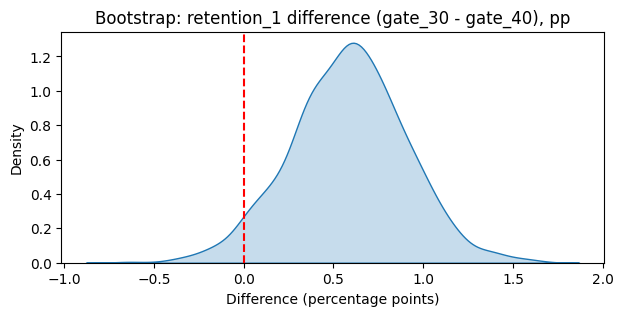

retention_7: 95% CI of difference = [0.30, 1.33] pp | P(gate_30 better) = 100.0%


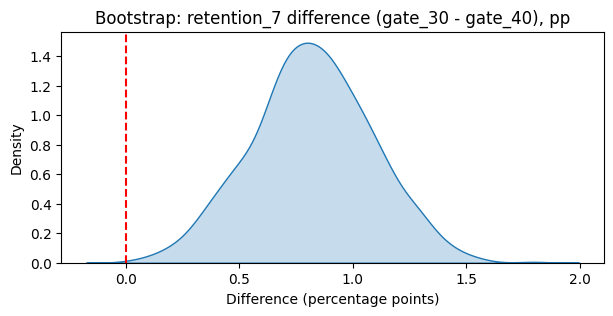

In [7]:
np.random.seed(42)
boot = []
for i in range(1000):
    sample = df.sample(frac=1, replace=True)
    boot.append(sample.groupby('version')[['retention_1','retention_7']].mean().unstack())
boot = pd.DataFrame(boot)

for metric in ['retention_1', 'retention_7']:
    diff = (boot[(metric,'gate_30')] - boot[(metric,'gate_40')]) * 100
    ci_low, ci_high = diff.quantile([0.025, 0.975])
    prob = (diff > 0).mean() * 100
    print(f"{metric}: 95% CI of difference = [{ci_low:.2f}, {ci_high:.2f}] pp | "
          f"P(gate_30 better) = {prob:.1f}%")

    plt.figure(figsize=(7,3))
    sns.kdeplot(diff, fill=True)
    plt.axvline(0, color='red', linestyle='--')
    plt.title(f'Bootstrap: {metric} difference (gate_30 - gate_40), pp')
    plt.xlabel('Difference (percentage points)')
    plt.savefig(f'../images/bootstrap_{metric}.png', bbox_inches='tight')
    plt.show()

## Bootstrap Confidence Intervals (1,000 resamples)

| Metric | 95% CI of difference (gate_30 − gate_40) | P(gate_30 better) | Conclusion |
|---|---|---|---|
| Day-1 retention | [−0.04, 1.20] pp | 96.3% | CI includes 0 → inconclusive |
| Day-7 retention | [0.30, 1.33] pp | >99.9% | CI excludes 0 → **gate_40 reduces retention** |

- Bootstrap (assumption-free) confirms the z-test results, making the conclusion robust.
- Day-7 drop is plausibly between 0.30 and 1.33 pp.

In [8]:
installs_per_month = 1_000_000   # assumption for illustration
r7 = df.groupby('version')['retention_7'].mean()

abs_drop = r7['gate_30'] - r7['gate_40']
rel_drop = abs_drop / r7['gate_30'] * 100
lost_players = abs_drop * installs_per_month

print(f"Absolute day-7 drop: {abs_drop*100:.2f} pp")
print(f"Relative day-7 drop: {rel_drop:.1f}%")
print(f"Lost day-7 retained players per 1M installs: ~{lost_players:,.0f}")
print(f"Range (using 95% CI): ~{0.0030*installs_per_month:,.0f} to ~{0.0133*installs_per_month:,.0f}")

Absolute day-7 drop: 0.82 pp
Relative day-7 drop: 4.3%
Lost day-7 retained players per 1M installs: ~8,183
Range (using 95% CI): ~3,000 to ~13,300


## Business Impact
- Absolute day-7 retention drop: **0.82 pp** | Relative drop: **4.3%**
- Assuming 1M installs/month (illustrative), gate_40 would lose **~8,200 day-7 retained players per month** (95% CI range: ~3,000 to ~13,300).
- Since retained players drive in-app purchase revenue, even the lower bound represents meaningful lost value.

## Recommendation: Do NOT ship gate_40 — keep the gate at level 30

**Evidence**
- Day-7 retention dropped 0.82 pp (19.02% → 18.20%), statistically significant (z = 3.157, p = 0.0016; bootstrap 95% CI [0.30, 1.33] pp).
- Day-1 retention showed no significant change (p = 0.074), so the harm appears in longer-term engagement.
- ~75% of the day-7 gap comes from players with 40–99 rounds — the group that hits the level-40 gate in the test version.

**Likely explanation (hypothesis)**
- An earlier gate (level 30) forces a break before players burn out, which may keep them coming back longer. Delaying the gate lets players binge and lose interest sooner.

**Limitations**
- Sample ratio mismatch detected (p = 0.0085); assignment/logging should be audited.
- No revenue or in-app purchase data — impact on monetization is inferred, not measured.
- Only 14 days of data; long-term (30-day+) effects unknown.
- Segment analysis uses a post-treatment variable (rounds played), so it is descriptive, not causal.

**Next steps**
1. Audit the randomization pipeline (SRM).
2. Re-run with revenue data to measure monetization impact.
3. Test an intermediate gate (e.g., level 35) or a lighter gate mechanic.
4. Track 30-day retention.